---

# Conference Popularity and Association Pattern Mining pada Dataset DBLP

*Notebook 03: Task 4, Frequent Pattern Mining dengan Apriori.*

---

## Kelompok Tugas Besar Data Mining

- Izhar Alif Akbar (18223129)
- Harfhan Ikhtiar (18223123)
- Mahesa Andre (13523140)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Implementasi Apriori**](#3)
4. [**Eksperimen Empat Min Support (Task 4.1)**](#4)
5. [**Validasi dengan mlxtend dan FP-Growth**](#5)
6. [**Analisis Frequent Itemsets (Task 4.2 sampai 4.5)**](#6)
7. [**Interpretasi (Task 4.6)**](#7)
8. [**Ringkasan dan Langkah Berikutnya**](#8)

---

# Introduction <a name="1"></a>

---

## Overview

*Task 4 mencari kombinasi konferensi yang sering muncul bersama dalam riwayat publikasi author. Notebook ini mengerjakan sisi Apriori pada author-based transactional database dari notebook `02_transactions`. Sisi FP-Growth dikerjakan pada notebook `04_fpgrowth`, dan perbandingan performa keduanya pada notebook `06_performance`.*

## Aim

*Task 4.1: menemukan frequent itemsets pada min support 0,1%, 0,5%, 1%, dan 2%.*

*Task 4.2 dan 4.3: memisahkan 1-, 2-, dan 3-itemsets, lalu menampilkan 10 itemsets dengan support tertinggi.*

*Task 4.4 dan 4.5: menganalisis pengaruh min support terhadap jumlah itemsets dan kandidat, serta mengidentifikasi kombinasi konferensi yang paling sering muncul bersama.*

*Task 4.6: menginterpretasikan pola yang ditemukan.*

## Metric

***Support** itemset $X$ adalah proporsi transaksi yang memuat seluruh item pada $X$. Penyebutnya selalu seluruh transaksi author-based, yaitu 1.821.757, termasuk transaksi yang dilewati saat penghitungan kandidat.*

$$\text{support}(X) = \frac{|\{t \in D : X \subseteq t\}|}{|D|}$$

*Itemset frequent jika support-nya minimal min support. Dalam hitungan transaksi, ambangnya adalah bilangan bulat terkecil $c$ dengan $c / |D| \ge \text{min\_sup}$, sama dengan FP-Growth (`fpgrowth.min_count_for`).*

## Approach

*Apriori bekerja per level. Level $k$ membangkitkan kandidat $C_k$ dari frequent $(k-1)$-itemsets $L_{k-1}$ (langkah join), membuang kandidat yang memiliki subset $(k-1)$ tidak frequent (langkah prune, sifat Apriori), lalu memindai database untuk menghitung support kandidat yang tersisa. Proses berhenti ketika $L_k$ kosong.*

*Pra-pemrosesan dibuat sama dengan FP-Growth agar perbandingan waktu di notebook 06 adil: item yang tidak frequent dipangkas, transaksi dengan kurang dari dua item frequent dilewati (tetap dihitung di penyebut), dan transaksi yang identik setelah dipangkas digabung lalu dihitung sekali dengan bobotnya. Saat menghitung kandidat, setiap transaksi memakai cara yang lebih murah: mengenumerasi $k$-subset transaksi, atau memeriksa setiap kandidat sebagai subset transaksi.*

*Kode algoritma berada di `src/apriori.py` dan sudah diuji dengan `pytest` (`tests/test_apriori_contract.py`: contoh buku teks, transaksi kosong di penyebut, dan brute force). Isi modul ditampilkan pada bagian 3.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook ini tidak memakai GPU. Prasyaratnya adalah notebook `02_transactions` sudah dijalankan sehingga `data/processed/tx_author.parquet` dan `tx_items.csv` tersedia.

Sel berikut memasang semua pustaka yang dipakai notebook ini.

In [1]:
%pip install -q --disable-pip-version-check numpy pandas scipy matplotlib pyarrow mlxtend

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Seluruh `import` untuk notebook ini dikumpulkan di satu sel. Modul proyek di `src/` diimpor setelah `Settings` menetapkan path-nya.

In [2]:
import inspect
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

## Seed Everything

Apriori bersifat deterministik. Seed tetap ditetapkan agar konsisten dengan notebook lain.

In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Seluruh path, ambang min support, dan warna dipusatkan di kelas `Settings`. Palet warna sama dengan notebook sebelumnya.

In [4]:
class Settings:
    SEED = 42
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

    SRC_DIR = ROOT / "src"
    PROC_DIR = ROOT / "data" / "processed"
    TAB_DIR = ROOT / "outputs" / "tables"
    FIG_DIR = ROOT / "outputs" / "figures"
    APR_DIR = ROOT / "outputs" / "apriori"

    ITEMS = PROC_DIR / "tx_items.csv"
    TX_AUTHOR = PROC_DIR / "tx_author.parquet"

    MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]
    TOP_K = 10

    INK = "#0b0b0b"
    INK_2 = "#52514e"
    MUTED = "#898781"
    GRID = "#e1e0d9"
    BASELINE = "#c3c2b7"
    SURFACE = "#fcfcfb"
    BLUE = "#2a78d6"
    BLUE_LIGHT = "#9ec5f4"
    ORANGE = "#eb6834"
    GRAY = "#b9b8b2"

CFG = Settings()
for d in (CFG.TAB_DIR, CFG.FIG_DIR, CFG.APR_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(CFG.SRC_DIR))
import apriori as apriori_module
from apriori import apriori
from fpgrowth import fpgrowth, to_frame
from fpm_data import load_horizontal, load_item_names
from validation import compare_itemsets, mlxtend_reference

Gaya grafik dan fungsi bantu diatur sekali di sini. Angka ditulis dengan pemisah ribuan titik dan desimal koma agar konsisten dengan notebook sebelumnya.

In [5]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": CFG.SURFACE, "axes.facecolor": CFG.SURFACE, "savefig.facecolor": CFG.SURFACE,
    "font.size": 9.5, "text.color": CFG.INK, "axes.labelcolor": CFG.INK_2,
    "xtick.color": CFG.INK_2, "ytick.color": CFG.INK_2, "axes.edgecolor": CFG.BASELINE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CFG.GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)


def fmt_id(value, digits=0):
    text = f"{value:,.{digits}f}"
    return text.replace(",", "X").replace(".", ",").replace("X", ".")


def pct_id(value, digits=1):
    return f"{value:.{digits}f}".replace(".", ",") + "%"


def save_fig(fig, name):
    fig.savefig(CFG.FIG_DIR / name)
    plt.show()


def save_table(df, name, index=True):
    df.to_csv(CFG.TAB_DIR / name, index=index)


def id_ticks(ax, axis="x"):
    formatter = FuncFormatter(lambda v, _: fmt_id(v, 0 if float(v).is_integer() else 1))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)


def tag(ms):
    return f"{ms * 100:g}".replace(".", "p")

## Load Dataset

Tabel panjang author-based diubah ke bentuk horizontal, yaitu list frozenset kode item per transaksi. Bentuk ini sama dengan masukan FP-Growth pada notebook 04. Waktu pemuatan tidak termasuk pengukuran.

In [6]:
transactions = load_horizontal(CFG.TX_AUTHOR)
names = load_item_names(CFG.ITEMS)
N = len(transactions)
print(f"Transaksi: {fmt_id(N)} | item unik: {fmt_id(len(names))}")

Transaksi: 1.821.757 | item unik: 4.373


---

# Implementasi Apriori <a name="3"></a>

---

## 3.1 Kode

Seluruh isi `src/apriori.py` ditampilkan di bawah. `generate_candidates` menjalankan langkah join dan prune, `count_candidates` memindai database berbobot, dan `apriori` mengulang keduanya per level. Hasilnya mencatat jumlah kandidat $|C_k|$ dan waktu setiap level.

In [7]:
print(inspect.getsource(apriori_module))

"""Apriori (Agrawal dan Srikant, 1994) untuk transactional database berbentuk horizontal."""
from __future__ import annotations

import time
from collections import Counter
from dataclasses import dataclass
from itertools import combinations
from math import comb
from typing import Dict, FrozenSet, List, Sequence, Set, Tuple

from fpgrowth import min_count_for

Itemset = Tuple[int, ...]


@dataclass
class AprioriResult:
    itemsets: Dict[FrozenSet[int], int]
    n_transactions: int
    min_support: float
    min_count: int
    level_seconds: List[float]  # waktu tiap level k = 1, 2, ...; level 1 termasuk pra-pemrosesan
    n_candidates: List[int]  # |C_k| tiap level; level 1 = jumlah item unik


def generate_candidates(frequent: Sequence[Itemset]) -> Set[Itemset]:
    """Join L(k-1) dengan dirinya (prefiks k-2 item sama), lalu prune kandidat yang punya
    subset (k-1) tidak frequent. Itemset disimpan sebagai tuple terurut menaik."""
    prev = set(frequent)
    by_prefix: Dict[Itemse

## 3.2 Contoh Kecil

Sebelum dijalankan pada data DBLP, Apriori diperiksa pada contoh buku teks Han, Kamber, dan Pei (2012), sembilan transaksi dengan item I1 sampai I5 dan min support 2/9. Buku tersebut menghasilkan $|C_1| = 5$, $|C_2| = 10$, dan $|C_3| = 2$ setelah prune (I1 I2 I3 dan I1 I2 I5), dengan total 13 frequent itemsets.

In [8]:
toy = [frozenset(t) for t in ([1, 2, 5], [2, 4], [2, 3], [1, 2, 4], [1, 3], [2, 3], [1, 3], [1, 2, 3, 5], [1, 2, 3])]
toy_names = {i: f"I{i}" for i in range(1, 6)}
toy_result = apriori(toy, 2 / 9)
toy_frame = to_frame(toy_result, toy_names)
print("Kandidat per level:", toy_result.n_candidates)
print("Frequent per level:", toy_frame["length"].value_counts().sort_index().tolist())
toy_frame[["names", "length", "count", "support"]]

Kandidat per level: [5, 10, 2]
Frequent per level: [5, 6, 2]


,names,length,count,support
0,I2,1,7,0.777778
1,I1,1,6,0.666667
2,I3,1,6,0.666667
3,I1 + I2,2,4,0.444444
4,I1 + I3,2,4,0.444444
5,I2 + I3,2,4,0.444444
6,I4,1,2,0.222222
7,I5,1,2,0.222222
8,I1 + I5,2,2,0.222222
9,I2 + I4,2,2,0.222222


---

# Eksperimen Empat Min Support (Task 4.1) <a name="4"></a>

---

Apriori dijalankan sekali untuk setiap min support. Jumlah kandidat, jumlah frequent itemsets, dan waktu setiap level dicatat. Waktu level 1 sudah termasuk pra-pemrosesan (pemindaian pertama, pemangkasan, dan penggabungan transaksi). Pengukuran berulang untuk perbandingan performa dilakukan pada notebook 06.

In [9]:
results = {}
for ms in CFG.MIN_SUPPORTS:
    res = apriori(transactions, ms)
    results[ms] = res
    print(f"min_sup {pct_id(ms * 100)} | min_count {fmt_id(res.min_count)} | itemsets {fmt_id(len(res.itemsets))} "
          f"| level {len(res.level_seconds)} | total {sum(res.level_seconds):.2f} s")

frames = {ms: to_frame(res, names) for ms, res in results.items()}
for ms, df in frames.items():
    df.assign(itemset=df["itemset"].apply(list)).to_parquet(CFG.APR_DIR / f"itemsets_{tag(ms)}.parquet", index=False)

min_sup 0,1% | min_count 1.822 | itemsets 1.514 | level 6 | total 6.02 s


min_sup 0,5% | min_count 9.109 | itemsets 88 | level 3 | total 1.73 s


min_sup 1,0% | min_count 18.218 | itemsets 30 | level 2 | total 0.99 s


min_sup 2,0% | min_count 36.436 | itemsets 6 | level 2 | total 0.81 s


Tabel berikut merinci setiap level: jumlah kandidat $|C_k|$, jumlah frequent itemsets $|L_k|$, persentase kandidat yang ternyata frequent, dan waktu level tersebut.

In [10]:
level_rows = []
for ms, res in results.items():
    lk = frames[ms]["length"].value_counts()
    for k, (cands, secs) in enumerate(zip(res.n_candidates, res.level_seconds), start=1):
        level_rows.append({"min_support": ms, "k": k, "kandidat": cands, "frequent": int(lk.get(k, 0)),
                           "frequent_pct": round(100 * lk.get(k, 0) / cands, 2), "detik": round(secs, 3)})
levels = pd.DataFrame(level_rows)
save_table(levels, "t4_apriori_level.csv", index=False)
levels

,min_support,k,kandidat,frequent,frequent_pct,detik
0,0.001,1,4373,574,13.13,1.600
1,0.001,2,164451,393,0.24,2.981
2,0.001,3,1228,348,28.34,0.783
3,0.001,4,337,159,47.18,0.402
4,0.001,5,54,37,68.52,0.155
5,0.001,6,5,3,60.00,0.102
6,0.005,1,4373,66,1.51,1.312
7,0.005,2,2145,21,0.98,0.371
8,0.005,3,13,1,7.69,0.050
9,0.010,1,4373,29,0.66,0.869


---

# Validasi dengan mlxtend dan FP-Growth <a name="5"></a>

---

Setiap hasil dibandingkan dengan `mlxtend.frequent_patterns.fpgrowth` dan dengan FP-Growth proyek (`src/fpgrowth.py`) pada database yang sama. Itemset dan count harus identik dengan keduanya.

In [11]:
check_rows = []
for ms, res in results.items():
    for ref_name, ref in (("mlxtend", mlxtend_reference(transactions, ms)),
                          ("fpgrowth", fpgrowth(transactions, ms, keep_tree=False).itemsets)):
        check_rows.append({"min_support": ms, "pembanding": ref_name, **compare_itemsets(res.itemsets, ref)})
checks = pd.DataFrame(check_rows)
save_table(checks, "t4_apriori_validasi.csv", index=False)
assert checks["identical"].all(), "hasil Apriori berbeda dengan pembanding"
checks

,min_support,pembanding,n_ours,n_ref,missing,extra,count_mismatch,identical
0,0.001,mlxtend,1514,1514,0,0,0,True
1,0.001,fpgrowth,1514,1514,0,0,0,True
2,0.005,mlxtend,88,88,0,0,0,True
3,0.005,fpgrowth,88,88,0,0,0,True
4,0.010,mlxtend,30,30,0,0,0,True
5,0.010,fpgrowth,30,30,0,0,0,True
6,0.020,mlxtend,6,6,0,0,0,True
7,0.020,fpgrowth,6,6,0,0,0,True


---

# Analisis Frequent Itemsets (Task 4.2 sampai 4.5) <a name="6"></a>

---

## 6.1 Jumlah Itemset per Ukuran (Task 4.2)

Itemset dikelompokkan menurut ukurannya. Kolom `k4+` menampung itemset berisi empat item atau lebih.

In [12]:
def length_counts(df):
    return df["length"].clip(upper=4).value_counts().reindex([1, 2, 3, 4], fill_value=0)

summary = pd.DataFrame([
    {"min_support": ms, "min_count": res.min_count, "itemsets": len(res.itemsets),
     **dict(zip(["k1", "k2", "k3", "k4+"], length_counts(frames[ms]).tolist())),
     "max_length": int(frames[ms]["length"].max()),
     "kandidat_total": sum(res.n_candidates[1:]), "t_total_s": round(sum(res.level_seconds), 3)}
    for ms, res in results.items()
])
save_table(summary, "t4_apriori_ringkasan.csv", index=False)
summary

,min_support,min_count,itemsets,k1,k2,k3,k4+,max_length,kandidat_total,t_total_s
0,0.001,1822,1514,574,393,348,199,6,166075,6.023
1,0.005,9109,88,66,21,1,0,3,2158,1.733
2,0.010,18218,30,29,1,0,0,2,406,0.988
3,0.020,36436,6,6,0,0,0,1,15,0.809


> Jumlah dan ukuran itemset sama persis dengan FP-Growth pada notebook 04: 1.514 itemset pada 0,1% (574 1-itemset, 393 pasangan, 348 triple, dan 199 itemset berukuran empat sampai enam), 88 pada 0,5%, 30 pada 1%, dan 6 pada 2%. Yang khas Apriori adalah kolom `kandidat_total`, yaitu jumlah kandidat level 2 ke atas yang support-nya harus dihitung: 166.075 pada 0,1%, 2.158 pada 0,5%, 406 pada 1%, dan 15 pada 2%. Untuk menemukan 940 itemset berukuran dua atau lebih pada 0,1%, Apriori menghitung 166.075 kandidat, 177 kali jumlah itemset yang akhirnya frequent.

## 6.2 Sepuluh Itemset dengan Support Tertinggi (Task 4.3)

Seperti pada notebook 04, ditampilkan sepuluh teratas untuk semua ukuran dan untuk itemset berukuran dua atau lebih.

In [13]:
cols = ["names", "length", "count", "support"]
for ms, df in frames.items():
    top = df.head(CFG.TOP_K)[cols]
    top_k2 = df[df["length"] >= 2].head(CFG.TOP_K)[cols]
    save_table(top, f"t4_apriori_top10_{tag(ms)}.csv", index=False)
    save_table(top_k2, f"t4_apriori_top10_k2plus_{tag(ms)}.csv", index=False)
    print(f"\nmin_sup {pct_id(ms * 100)}: semua ukuran")
    display(top.style.format({"support": "{:.4%}"}))
    print(f"min_sup {pct_id(ms * 100)}: ukuran >= 2 ({len(df[df['length'] >= 2])} itemset)")
    display(top_k2.style.format({"support": "{:.4%}"}))


min_sup 0,1%: semua ukuran


,names,length,count,support
0,NeurIPS,1,57800,3.1728%
1,CVPR,1,47664,2.6164%
2,AAAI,1,46437,2.5490%
3,ICASSP,1,42057,2.3086%
4,EMBC,1,39318,2.1582%
5,HCI,1,37884,2.0795%
6,IGARSS,1,35229,1.9338%
7,EMNLP,1,33954,1.8638%
8,ICML,1,31896,1.7508%
9,IROS,1,31249,1.7153%


min_sup 0,1%: ukuran >= 2 (940 itemset)


,names,length,count,support
29,ICML + NeurIPS,2,18503,1.0157%
31,ICLR + NeurIPS,2,17852,0.9799%
34,AAAI + NeurIPS,2,15973,0.8768%
36,CVPR + NeurIPS,2,15640,0.8585%
38,CVPR + ICCV,2,15441,0.8476%
48,ACL + EMNLP,2,14557,0.7991%
54,CVPR + ECCV,2,13752,0.7549%
56,ICLR + ICML,2,12947,0.7107%
60,AAAI + CVPR,2,12169,0.6680%
62,ICRA + IROS,2,11860,0.6510%



min_sup 0,5%: semua ukuran


,names,length,count,support
0,NeurIPS,1,57800,3.1728%
1,CVPR,1,47664,2.6164%
2,AAAI,1,46437,2.5490%
3,ICASSP,1,42057,2.3086%
4,EMBC,1,39318,2.1582%
5,HCI,1,37884,2.0795%
6,IGARSS,1,35229,1.9338%
7,EMNLP,1,33954,1.8638%
8,ICML,1,31896,1.7508%
9,IROS,1,31249,1.7153%


... (6 outputs left out)


min_sup 2,0%: semua ukuran


,names,length,count,support
0,NeurIPS,1,57800,3.1728%
1,CVPR,1,47664,2.6164%
2,AAAI,1,46437,2.5490%
3,ICASSP,1,42057,2.3086%
4,EMBC,1,39318,2.1582%
5,HCI,1,37884,2.0795%


min_sup 2,0%: ukuran >= 2 (0 itemset)


,names,length,count,support


> Sepuluh itemset teratas pada setiap min support selalu berupa konferensi tunggal, dipimpin NeurIPS (57.800 author, support 3,17%), CVPR (47.664), dan AAAI (46.437). Pasangan teratas, ICML + NeurIPS (18.503 author, support 1,02%), masih lebih kecil dari konferensi ke-10, IROS (31.249 author). Hasil ini sama dengan notebook 04 karena kedua algoritma menghasilkan itemset dan count yang identik.

## 6.3 Kandidat dan Frequent Itemsets per Level (Task 4.4)

Ciri khas Apriori adalah jumlah kandidat yang harus dihitung. Grafik berikut membandingkan $|C_k|$ dan $|L_k|$ per level untuk setiap min support. Sumbu y memakai skala log.

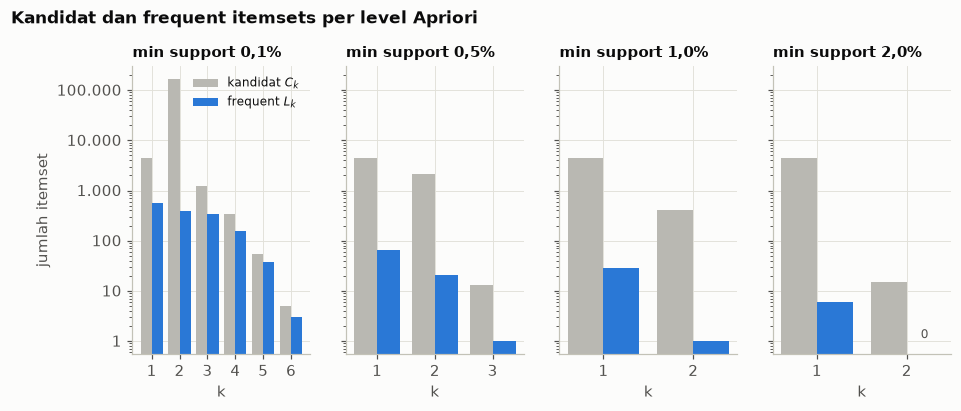

In [14]:
fig, axes = plt.subplots(1, len(CFG.MIN_SUPPORTS), figsize=(9.6, 3.4), sharey=True)
for ax, ms in zip(axes, CFG.MIN_SUPPORTS):
    lv = levels[levels["min_support"] == ms]
    x = lv["k"].to_numpy()
    ax.bar(x - 0.2, lv["kandidat"], 0.4, color=CFG.GRAY, label="kandidat $C_k$")
    ax.bar(x + 0.2, lv["frequent"], 0.4, color=CFG.BLUE, label="frequent $L_k$")
    for k in x[lv["frequent"].to_numpy() == 0]:
        ax.annotate("0", (k + 0.2, 1), ha="center", va="bottom", fontsize=8, color=CFG.INK_2)
    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xlabel("k")
    ax.set_title(f"min support {pct_id(ms * 100)}", fontsize=9.5)
id_ticks(axes[0], "y")
axes[0].set_ylabel("jumlah itemset")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Kandidat dan frequent itemsets per level Apriori", x=0.01, y=1.03, ha="left", fontweight="bold")
save_fig(fig, "t4_apriori_kandidat_level.png")

> Pada 0,1% terdapat 574 item frequent, sehingga $C_2$ berisi seluruh $574 	imes 573 / 2 = 164.451$ pasangan. Langkah prune tidak dapat membuang apa pun di level 2 karena setiap subset berukuran satu sudah frequent. Hanya 393 pasangan (0,24%) yang ternyata frequent, dan level 2 menjadi level termahal, hampir separuh total waktu. Mulai level 3 prune bekerja efektif: dari 393 pasangan hanya terbentuk 1.228 kandidat, dan persentase kandidat yang frequent naik dari 28% di level 3 menjadi 69% di level 5.
>
> Pada min support yang lebih tinggi, $L_1$ jauh lebih kecil (66, 29, dan 6 item), sehingga $C_2$ ikut mengecil secara kuadratik (2.145, 406, dan 15). Waktu kemudian didominasi level 1, yaitu pemindaian pertama 1,8 juta transaksi beserta pemangkasan dan penggabungannya, yang biayanya hampir tetap untuk semua min support. Penurunan min support dari 2% ke 0,1% menaikkan $|L_1|$ sekitar 96 kali, tetapi $|C_2|$ naik sekitar 11.000 kali. Inilah sumber biaya utama Apriori yang dibandingkan dengan FP-Growth pada notebook 06.

## 6.4 Kombinasi Konferensi yang Paling Sering Muncul Bersama (Task 4.5)

Pasangan dan triple teratas diambil dari hasil min support 0,1%. Kolom `bertahan_sampai` menunjukkan min support tertinggi tempat kombinasi tersebut masih frequent.

In [15]:
base = frames[min(CFG.MIN_SUPPORTS)]

def survives(itemset):
    kept = [ms for ms in CFG.MIN_SUPPORTS if frozenset(itemset) in results[ms].itemsets]
    return pct_id(max(kept) * 100)

pairs = base[base["length"] == 2].head(CFG.TOP_K).copy()
triples = base[base["length"] == 3].head(CFG.TOP_K).copy()
for t in (pairs, triples):
    t["bertahan_sampai"] = t["itemset"].map(survives)
save_table(pairs[["names", "count", "support", "bertahan_sampai"]], "t4_apriori_pasangan_teratas.csv", index=False)
save_table(triples[["names", "count", "support", "bertahan_sampai"]], "t4_apriori_triple_teratas.csv", index=False)
display(pairs[["names", "count", "support", "bertahan_sampai"]].style.format({"support": "{:.4%}"}))
display(triples[["names", "count", "support", "bertahan_sampai"]].style.format({"support": "{:.4%}"}))

,names,count,support,bertahan_sampai
29,ICML + NeurIPS,18503,1.0157%,"1,0%"
31,ICLR + NeurIPS,17852,0.9799%,"0,5%"
34,AAAI + NeurIPS,15973,0.8768%,"0,5%"
36,CVPR + NeurIPS,15640,0.8585%,"0,5%"
38,CVPR + ICCV,15441,0.8476%,"0,5%"
48,ACL + EMNLP,14557,0.7991%,"0,5%"
54,CVPR + ECCV,13752,0.7549%,"0,5%"
56,ICLR + ICML,12947,0.7107%,"0,5%"
60,AAAI + CVPR,12169,0.6680%,"0,5%"
62,ICRA + IROS,11860,0.6510%,"0,5%"


,names,count,support,bertahan_sampai
72,ICLR + ICML + NeurIPS,10413,0.5716%,"0,5%"
104,CVPR + ECCV + ICCV,8474,0.4652%,"0,1%"
107,CVPR + ICCV + NeurIPS,8407,0.4615%,"0,1%"
127,AAAI + ICML + NeurIPS,7585,0.4164%,"0,1%"
135,AAAI + ICLR + NeurIPS,7371,0.4046%,"0,1%"
137,AAAI + CVPR + NeurIPS,7301,0.4008%,"0,1%"
142,CVPR + ECCV + NeurIPS,7272,0.3992%,"0,1%"
144,CVPR + ICLR + NeurIPS,7157,0.3929%,"0,1%"
167,AAAI + CVPR + ICCV,6477,0.3555%,"0,1%"
172,CVPR + ICML + NeurIPS,6259,0.3436%,"0,1%"


> Pasangan dan triple teratas sama dengan notebook 04. Pasangan teratas membentuk kelompok bidang: machine learning (ICML + NeurIPS, ICLR + NeurIPS, ICLR + ICML), computer vision (CVPR + ICCV, CVPR + ECCV), NLP (ACL + EMNLP), dan robotika (ICRA + IROS). ICML + NeurIPS adalah satu-satunya pasangan yang masih frequent pada 1%, dan ICLR + ICML + NeurIPS (10.413 author) satu-satunya triple yang masih frequent pada 0,5%. Analisis keterhubungan konferensi dan itemset terpanjang ada pada notebook 04 bagian 6.5 dan tidak diulang di sini karena hasilnya identik.

---

# Interpretasi (Task 4.6) <a name="7"></a>

---

**Pola publikasi.** Karena frequent itemsets Apriori identik dengan FP-Growth, interpretasi polanya sama dengan notebook 04 bagian 7. Kombinasi konferensi yang frequent hampir seluruhnya terjadi di dalam satu bidang atau di antara bidang yang bertetangga dekat. NeurIPS menjadi penghubung inti AI, machine learning, dan computer vision, dan konferensi populer seperti EMBC, IGARSS, dan HCI hampir tidak membentuk pasangan frequent.

**Perilaku Apriori pada data ini.** Ekor panjang data DBLP membuat banyak konferensi lolos sebagai 1-itemset pada 0,1%, tetapi sangat sedikit pasangan yang lolos. Kombinasi ini adalah kasus terburuk bagi Apriori: kandidat level 2 tumbuh kuadratik terhadap $|L_1|$, sementara 99,76% di antaranya tidak frequent. Sebaliknya, karena pasangan frequent sedikit dan terkumpul di beberapa bidang, prune pada level 3 ke atas membuang hampir semua kombinasi sehingga level berikutnya murah.

**Pengaruh optimasi.** Waktu yang tercatat di sini sudah memakai pra-pemrosesan yang sama dengan FP-Growth (pemangkasan item, pelewatan transaksi pendek, dan penggabungan transaksi identik, yang memadatkan 536.543 transaksi berisi minimal dua item frequent menjadi 315.694 transaksi unik pada 0,1%), serta pemilihan cara penghitungan kandidat per transaksi. Tanpa pemilihan cara tersebut, transaksi terpanjang (187 item frequent pada 0,1%) membuat enumerasi subset meledak. Perbandingan waktu dengan FP-Growth secara berulang dilakukan pada notebook 06.

**Keterbatasan.** Keterbatasan data sama dengan notebook 04 bagian 7: item adalah seri konferensi berdasarkan key DBLP, identitas author mengikuti disambiguasi DBLP, support menghitung author bukan paper, dan transaksi author-based menggabungkan seluruh 2015-2025.

---

# Ringkasan dan Langkah Berikutnya <a name="8"></a>

---

| Task | Hasil | Bagian |
|---|---|---|
| 4.1 | Apriori pada empat min support menghasilkan 1.514, 88, 30, dan 6 frequent itemsets, identik dengan `mlxtend` dan FP-Growth notebook 04 | 4, 5 |
| 4.2 | 1-, 2-, dan 3-itemset: 574, 393, 348 (0,1%); 66, 21, 1 (0,5%); 29, 1, 0 (1%); 6, 0, 0 (2%) | 6.1 |
| 4.3 | Sepuluh teratas selalu konferensi tunggal (NeurIPS, CVPR, AAAI); pasangan teratas ICML + NeurIPS dengan support 1,02% | 6.2 |
| 4.4 | Kandidat level 2 ke atas: 166.075, 2.158, 406, dan 15; $C_2$ pada 0,1% berisi 164.451 pasangan dengan hanya 0,24% yang frequent | 6.3 |
| 4.5 | Pasangan teratas ICML + NeurIPS, ICLR + NeurIPS, AAAI + NeurIPS; triple teratas ICLR + ICML + NeurIPS | 6.4 |
| 4.6 | Pola sama dengan FP-Growth; biaya Apriori terkonsentrasi di level 2 karena ekor panjang data | 7 |

Frequent itemsets setiap min support disimpan di `outputs/apriori/itemsets_<tag>.parquet` dengan kolom yang sama dengan `outputs/fpgrowth/`. Rincian kandidat per level ada di `outputs/tables/t4_apriori_level.csv`. Notebook `06_performance` memanggil `src/apriori.py` untuk membandingkan waktu Apriori dan FP-Growth secara berulang.